**Before starting this practical session**:

1. **Change the runtime type on Google Colab**: `Runtime > Change runtime type > T4 GPU`
2. **Install the packages below**:

In [1]:
! pip install lightning torchmetrics torchinfo

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 849.3/849.3 kB 23.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 42.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 853.0/853.0 kB 45.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [lightning]


3. Run this code to suppress some messages and warnings that may be displayed.

In [2]:
import logging
logging.getLogger("lightning").setLevel(logging.ERROR)
logging.getLogger("lightning.pytorch.utilities.rank_zero").setLevel(logging.WARNING)
logging.getLogger("lightning.pytorch.accelerators.cuda").setLevel(logging.WARNING)
logger = logging.getLogger("lightning")
logger.propagate = False

import warnings
warnings.filterwarnings("ignore", ".*does not have many workers.*")
warnings.filterwarnings("ignore", ".*Missing logger folder.*")
warnings.filterwarnings("ignore", "`isinstance\\(treespec, LeafSpec\\)` is deprecated.*")

# Brain magnetic resonance image synthesis

## Introduction

Magnetic resonance imaging (MRI) is a medical imaging technique that provides two- or three-dimensional views of the inside of the body non-invasively with relatively high contrast resolution ([Wikipedia](https://en.wikipedia.org/wiki/Magnetic_resonance_imaging)).

There are different types of magnetic resonance images, called weightings.
In simplified terms, by changing the acquisition parameters, different images highlighting different characteristics are obtained.

Among the existing weightings, two are commonly used:

* **T1 weighting** highlights regions with fat, notably [adipose tissue](https://en.wikipedia.org/wiki/Adipose_tissue), and therefore brain regions containing a lot of adipose tissue.
* **T2 weighting** highlights fluids, notably [cerebrospinal fluid](https://en.wikipedia.org/wiki/Cerebrospinal_fluid), and therefore brain regions containing a lot of cerebrospinal fluid.

Full brain images are three-dimensional images.
However, visualization is easier for the human eye in two dimensions.
Two-dimensional slices are therefore generally used.
Since the three-dimensional image is a rectangular parallelepiped, there are three ways to slice a three-dimensional image, each associated with an axis whose value is fixed.

[<img src="https://raw.githubusercontent.com/johannfaouzi/smart-data-deep-learning/main/figures/coupes_irm.png" width="750" />](https://raw.githubusercontent.com/johannfaouzi/smart-data-deep-learning/main/figures/coupes_irm.png)

The image above illustrates these three types of slices: an axial slice (left), a coronal slice (middle), and a sagittal slice (right).
The axial slice provides the best coverage of the brain, so it is the slice generally used.

The image below illustrates two axial slices, with T1-weighting on the left and T2-weighting on the right.

[<img src="https://raw.githubusercontent.com/johannfaouzi/smart-data-deep-learning/main/figures/brain_mri_t1_t2.png" width="500" />](https://raw.githubusercontent.com/johannfaouzi/smart-data-deep-learning/main/figures/brain_mri_t1_t2.png)

**The goal of this practical session is to generate the T2 image from the T1 image**.
The practical value of this approach is to reduce the use of MRI machines: only a single acquisition would be needed to obtain both weightings.


## (Down)loading the dataset

We will work on a public dataset called the [IXI dataset](http://brain-development.org/ixi-dataset/).
The preprocessed data is available on this [GitHub repository](https://github.com/Easternwen/IXI-dataset).
In the `size64` folder, there are $1154$ files, corresponding to $2$ images for each of the $577$ subjects.
The size of each image is $(64, 64)$.

The following command clones the GitHub repository into the newly created `data` folder.

In [3]:
! mkdir -p data && cd data && (test -d IXI-dataset || git clone https://github.com/Easternwen/IXI-dataset)

Cloning into 'IXI-dataset'...
remote: Enumerating objects: 1157, done.
remote: Counting objects: 100% (1157/1157), done.
remote: Compressing objects: 100% (1156/1156), done.
remote: Total 1157 (delta 0), reused 1157 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (1157/1157), 24.99 MiB | 28.72 MiB/s, done.


Let's visualize a few images from the dataset using the `plot_images_one_subject()` function defined below.

In [4]:
import matplotlib.pyplot as plt
import os
import torch


def plot_images_one_subject(idx=None):
    """Plots the T1- and T2-weighted axial slices of a given subject.

    Parameters
    ----------
    idx : int (default = None)
        Index of the subject. The list of valid indices is available
        below (in the `idx_valid` variable). If the index is not
        provided or is invalid, a random valid index is drawn.
    """
    idx_valid = [
         2,  12,  13,  14,  15,  16,  17,  19,  20,  21,  22,  23,  24,
        25,  26,  27,  28,  29,  30,  31,  33,  34,  35,  36,  37,  38,
        39,  40,  41,  42,  43,  44,  45,  46,  48,  49,  50,  51,  52,
        53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,  65,
        66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,  78,
        79,  80,  81,  83,  84,  85,  86,  87,  88,  89,  90,  91,  92,
        93,  94,  95,  96,  97,  98,  99, 100, 101, 102, 103, 104, 105,
       106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 117, 118, 119,
       120, 121, 122, 123, 126, 127, 128, 129, 130, 131, 132, 134, 135,
       136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 148, 150,
       151, 153, 154, 156, 157, 158, 159, 160, 161, 162, 163, 164, 165,
       166, 167, 168, 169, 170, 172, 173, 174, 175, 176, 177, 178, 179,
       180, 181, 183, 184, 185, 186, 188, 189, 191, 192, 193, 194, 195,
       196, 197, 198, 199, 200, 201, 202, 204, 205, 206, 207, 208, 209,
       210, 211, 212, 213, 214, 216, 217, 218, 219, 221, 222, 223, 224,
       225, 226, 227, 228, 229, 230, 231, 232, 233, 234, 236, 237, 238,
       239, 240, 241, 242, 244, 246, 247, 248, 249, 250, 251, 252, 253,
       254, 255, 256, 257, 258, 259, 260, 261, 262, 263, 264, 265, 266,
       267, 268, 269, 270, 274, 275, 276, 277, 278, 279, 280, 282, 284,
       285, 286, 287, 288, 289, 290, 291, 292, 293, 294, 295, 296, 297,
       298, 299, 300, 302, 303, 304, 305, 306, 307, 308, 310, 311, 312,
       313, 314, 315, 316, 317, 318, 319, 320, 321, 322, 324, 325, 326,
       327, 328, 329, 330, 331, 332, 333, 334, 335, 336, 337, 338, 340,
       341, 342, 344, 345, 347, 348, 350, 351, 353, 354, 356, 357, 358,
       359, 360, 361, 362, 363, 364, 365, 367, 368, 369, 370, 371, 372,
       373, 375, 376, 377, 378, 379, 380, 381, 382, 383, 384, 385, 386,
       387, 388, 389, 390, 391, 392, 393, 394, 395, 396, 397, 398, 399,
       400, 401, 402, 403, 404, 405, 406, 407, 408, 409, 410, 411, 412,
       413, 414, 415, 416, 417, 418, 419, 420, 422, 423, 424, 425, 426,
       427, 428, 429, 430, 431, 432, 433, 434, 435, 436, 437, 438, 439,
       440, 441, 442, 443, 444, 445, 446, 447, 448, 449, 450, 451, 452,
       453, 454, 455, 456, 457, 458, 459, 460, 461, 462, 463, 464, 465,
       467, 468, 469, 470, 473, 474, 475, 476, 477, 478, 479, 480, 481,
       482, 483, 484, 485, 486, 487, 488, 489, 490, 491, 492, 493, 494,
       495, 496, 497, 498, 499, 501, 502, 503, 504, 505, 506, 507, 508,
       510, 511, 512, 515, 516, 517, 518, 519, 521, 522, 523, 524, 525,
       526, 527, 528, 531, 532, 533, 534, 535, 536, 537, 538, 539, 541,
       542, 543, 544, 546, 547, 548, 549, 550, 551, 552, 553, 554, 555,
       556, 558, 559, 560, 561, 562, 563, 565, 566, 567, 568, 569, 571,
       572, 573, 574, 575, 576, 577, 578, 579, 582, 584, 585, 586, 587,
       588, 589, 591, 592, 593, 594, 595, 596, 597, 598, 599, 600, 601,
       603, 605, 606, 607, 608, 609, 610, 611, 612, 613, 614, 616, 617,
       618, 619, 621, 622, 623, 625, 626, 627, 629, 630, 631, 632, 633,
       634, 635, 636, 637, 638, 639, 640, 641, 642, 643, 644, 646, 648,
       651, 652, 653, 661, 662
    ]

    if not (isinstance(idx, int) and idx in idx_valid):
        import random
        idx = random.choice(idx_valid)

    plt.figure(figsize=(9, 4))

    plt.subplot(1, 2, 1)
    plt.imshow(
        torch.transpose(
            torch.load(
                os.path.join(
                    "data", "IXI-dataset", "size64", f"sub-IXI{idx:03} - T1.pt"
                ), weights_only=True
            ), 0, 1
        ), cmap="gray", origin="lower"
    )
    plt.title(f"T1 slice for subject {idx:03}")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(
        torch.transpose(
            torch.load(
                os.path.join(
                    "data", "IXI-dataset", "size64", f"sub-IXI{idx:03} - T2.pt"
                ), weights_only=True
            ), 0, 1),
        cmap="gray", origin="lower"
    )
    plt.title(f"T2 slice for subject {idx:03}")
    plt.axis("off")
    plt.show()

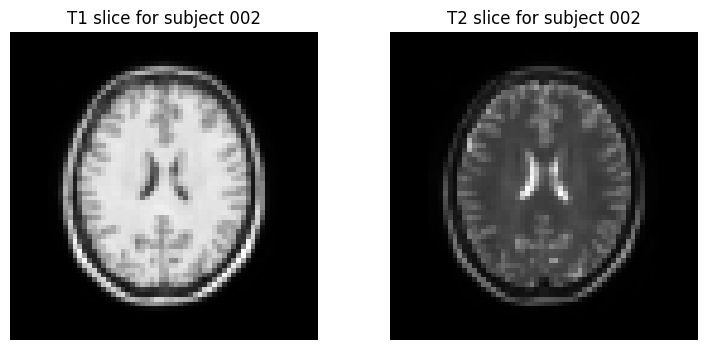

In [5]:
plot_images_one_subject(2)

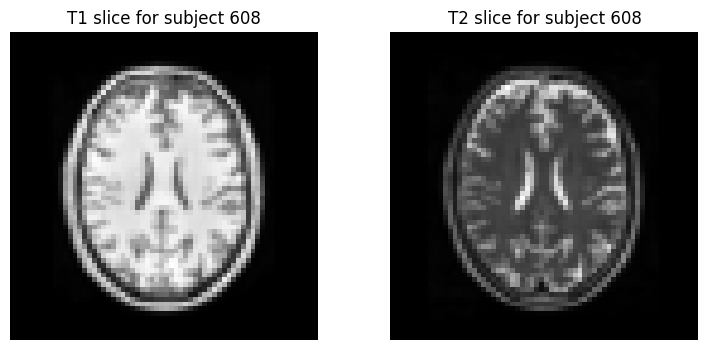

In [6]:
plot_images_one_subject(608)

We will now define our own class for this dataset.
80% of the dataset is used for the training set, and 20% for the validation set.
The `CustomDataset()` class defined below creates these two datasets.
We use it to create the *dataloaders* for the training and validation sets with batches of size $32$.

In [7]:
from torch.utils.data import Dataset, DataLoader


class CustomDataset(Dataset):
    """Custom class for the IXI data set.

    Parameters
    ----------
    train : bool
        If True, returns the training set. Otherwise, returns the validation set.

    """
    def __init__(self, train):

        root = os.path.join("data", "IXI-dataset", "size64")

        files = sorted(os.listdir(root))
        patient_id = sorted(set([i.split()[0] for i in files]))  # sorted for a reproducible split
        split_idx = int(0.8 * len(patient_id))
        imgs = []

        if train:
            for i in patient_id[:split_idx]:
                if (
                    os.path.isfile(os.path.join(root, f"{i} - T1.pt")) and
                    os.path.isfile(os.path.join(root, f"{i} - T2.pt"))
                ):
                    imgs.append((
                        os.path.join(root, f"{i} - T1.pt"),
                        os.path.join(root, f"{i} - T2.pt")
                    ))
        else:
            for i in patient_id[split_idx:]:
                if (
                    os.path.isfile(os.path.join(root, f"{i} - T1.pt")) and
                    os.path.isfile(os.path.join(root, f"{i} - T2.pt"))
                ):
                    imgs.append((
                        os.path.join(root, f"{i} - T1.pt"),
                        os.path.join(root, f"{i} - T2.pt")
                    ))

        self.imgs = imgs

    def __getitem__(self, index):
        t1_path, t2_path = self.imgs[index]

        # Add a dimension for the channels
        t1 = torch.unsqueeze(torch.load(t1_path, weights_only=True), 0).to(dtype=torch.float32)
        t2 = torch.unsqueeze(torch.load(t2_path, weights_only=True), 0).to(dtype=torch.float32)

        return t1, t2

    def __len__(self):
        return len(self.imgs)


# Datasets
dataset_train = CustomDataset(train=True)
dataset_val = CustomDataset(train=False)

# Dataloaders
batch_size = 32
dataloader_train = DataLoader(dataset_train, batch_size=batch_size, shuffle=True)
dataloader_val = DataLoader(dataset_val, batch_size=batch_size)

We check the size of the input and output images.
We only display the sizes for the first sample of the training set here, but we will assume this information holds for all the samples (which is indeed the case).

In [8]:
print(f"Size of a T1 image = {tuple(dataset_train[0][0].size())}")
print(f"Size of a T2 image = {tuple(dataset_train[0][1].size())}")

Size of a T1 image = (1, 64, 64)
Size of a T2 image = (1, 64, 64)


In [9]:
image_size = tuple(dataset_train[0][0].size())

## Generator

In this section, we will train a generator to generate the T2 image from the T1 image.
This is made possible by the fact that the dataset is paired: we have access to the T1 and T2 images of the same subject.

### Question 1

Fill in the missing code in the `__init__()` and `forward()` methods of the `Generator()` class defined below using the information provided in the text below.

#### Architecture

Our generator will have a **U-Net** type architecture with the following characteristics:

* The downsampling blocks consist of a convolutional layer, followed by a normalization layer, and finally the ReLU activation function.

* The upsampling blocks consist of a transposed convolutional layer, followed by a normalization layer, and finally the ReLU activation function.

* The final block consists of an upsampling layer, a convolutional layer with 1 output channel, and the hyperbolic tangent to scale the pixel values between -1 and 1.

The exact architecture, with the hyperparameter values for each layer, is shown in the image below.
If a layer takes two feature maps as input, they are concatenated (along the channel dimension).
The code for the classes corresponding to the different blocks is already provided below: `UNetDown()`, `UNetUp()`, and `UNetFinal()` correspond to the downsampling blocks, upsampling blocks, and final block respectively.

[<img src="https://raw.githubusercontent.com/johannfaouzi/smart-data-deep-learning/main/figures/generator.png" width="750" />](https://raw.githubusercontent.com/johannfaouzi/smart-data-deep-learning/main/figures/generator.png)

#### Training

The model will be trained using the mean absolute error as the loss function.
You can use [`torch.nn.L1Loss()`](https://pytorch.org/docs/stable/generated/torch.nn.L1Loss.html).

#### Evaluation metrics

The performance of a model will be evaluated using the [*structural similarity index measure*](https://en.wikipedia.org/wiki/Structural_similarity_index_measure) (SSIM).
Explanations regarding this metric will be provided later in this notebook.
For now, all you need to know is that it is a score between $0$ (worst) and $1$ (best) and that it is already implemented in the `torchmetrics` package: [`torchmetrics.image.StructuralSimilarityIndexMeasure()`](https://lightning.ai/docs/torchmetrics/stable/image/structural_similarity.html).

In [10]:
class UNetDown(torch.nn.Module):
    """Downsampling block.

    Parameters
    ----------
    in_channels : int
        Number of input channels.

    out_channels : int
        Number of output channels.
    """
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.model = torch.nn.Sequential(
            torch.nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=2, padding=1),
            torch.nn.InstanceNorm2d(out_channels),
            torch.nn.ReLU()
          )

    def forward(self, x):
        return self.model(x)


class UNetUp(torch.nn.Module):
    """Upsampling block.

    Parameters
    ----------
    in_channels : int
        Number of input channels.

    out_channels : int
        Number of output channels.
    """
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.model = torch.nn.Sequential(
            torch.nn.ConvTranspose2d(
                in_channels, out_channels, kernel_size=4, stride=2, padding=1
            ),
            torch.nn.InstanceNorm2d(out_channels),
            torch.nn.ReLU()
        )

    def forward(self, x, skip_input=None):
        if skip_input is not None:
            dim = 0 if x.ndim == 3 else 1
            x = torch.cat((x, skip_input), dim)  # add the skip connection
        return self.model(x)


class UNetFinal(torch.nn.Module):
    """Final block.

    Parameters
    ----------
    in_channels : int
        Number of input channels.

    out_channels : int
        Number of output channels.
    """
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.model = torch.nn.Sequential(
            torch.nn.Upsample(scale_factor=2),
            torch.nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            torch.nn.Tanh(),
        )

    def forward(self, x, skip_input=None):
        if skip_input is not None:
            dim = 0 if x.ndim == 3 else 1
            x = torch.cat((x, skip_input), dim)  # add the skip connection
        return self.model(x)

In [12]:
import lightning as L
from torchmetrics.image import StructuralSimilarityIndexMeasure


class Generator(L.LightningModule):  # Always inherit from the lightning.LightningModule class
    """Class for the generator.

    Parameters
    ----------
    in_channels : int (default = 1)
        Number of input channels.

    out_channels : int (default = 1)
        Number of output channels.

    lr : float (default = 1e-3)
        Learning rate.

    betas : tuple[float, float] (default = (0.9, 0.999))
        Betas hyperparameters of the Adam optimization algorithm.
    """
    def __init__(self, in_channels=1, out_channels=1, lr=1e-3, betas=(0.9, 0.999)):
        """Constructor."""
        super().__init__()  # Always run the constructor of the parent class

        self.lr = lr
        self.betas = betas

        ### BEGIN TODO ###
        # Instantiate the blocks of the architecture

        self.down1 = UNetDown(in_channels, 64)
        self.down2 = UNetDown(64, 128)
        self.down3 = UNetDown(128, 256)
        self.down4 = UNetDown(256, 512)
        self.down5 = UNetDown(512, 512)

        self.up1 = UNetUp(512, 512)
        self.up2 = UNetUp(1024, 256)
        self.up3 = UNetUp(512, 128)
        self.up4 = UNetUp(256, 64)

        self.final = UNetFinal(128, out_channels)

        # Instantiate the loss function
        self.loss = torch.nn.L1Loss()
        #### END TODO ####

        # Instantiate the metrics
        self.ssim_train = StructuralSimilarityIndexMeasure(data_range=(-1.0, 1.0))
        self.ssim_val = StructuralSimilarityIndexMeasure(data_range=(-1.0, 1.0))

    def forward(self, x):
        """Performs the forward pass.

        Parameters
        ----------
        x : Tensor, shape = (batch_size, n_channels, height, width)
            True T1-weighted images.

        Returns
        -------
        y_pred : Tensor, shape = (batch_size, n_channels, height, width)
            Generated T2-weighted images.
        """
        ### BEGIN TODO ###
        d1 = self.down1(x)
        d2 = self.down2(d1)
        d3 = self.down3(d2)
        d4 = self.down4(d3)
        d5 = self.down5(d4)
        u1 = self.up1(d5)
        u2 = self.up2(u1, d4)
        u3 = self.up3(u2, d3)
        u4 = self.up4(u3, d2)
        y_pred = self.final(u4, d1)
        #### END TODO ####
        return y_pred

    def step(self, batch, dataset):
        """Perform a step.

        A step consists in mapping a batch of samples to the loss function for this batch of input samples.

        Parameters
        ----------
        batch : list[Tensor, Tensor]
            Batch of samples. The first tensor consists of the T1-weighted images,
            while the second tensor consists of the T2-weighted images.

        dataset : {"training", "validation"}
            Data set used.

        Returns
        -------
        loss : Tensor, shape = (1,)
            Loss function evaluated for this batch of samples.
        """
        x, y = batch
        y_pred = self(x)
        loss = self.loss(y_pred, y)

        if dataset == "training":
            metric = self.ssim_train
            name = "train"
            bar_step = True
        else:
            metric = self.ssim_val
            name = "val"
            bar_step = False

        ssim = metric(y_pred, y)
        self.log(f"loss_{name}", loss, prog_bar=bar_step, on_step=bar_step, on_epoch=True)
        self.log(f"ssim_{name}", ssim, prog_bar=bar_step, on_step=bar_step, on_epoch=True)

        return loss

    def training_step(self, batch):
        """Perform a training step."""
        return self.step(batch, "training")

    def validation_step(self, batch):
        """Perform a validation step."""
        return self.step(batch, "validation")

    def on_train_start(self):
        """Code to run at the beginning of training."""
        string = f"Version {self.trainer.logger.version}"
        print(f"{string}\n{'=' * len(string)}\n")

    def on_train_epoch_end(self):
        """Code to run at the end of each training epoch."""
        metrics = self.trainer.callback_metrics
        string = (f"""
            Epoch {self.trainer.current_epoch + 1} / {self.trainer.max_epochs}
            -----------------------------------------
            |  Data set  | Loss function |   SSIM   |
            | ---------- | ------------- | -------- |
            |  Training  |{metrics['loss_train'].item():^15.7f}|{metrics['ssim_train'].item():^10.6f}|
            | Validation |{metrics['loss_val'].item():^15.7f}|{metrics['ssim_val'].item():^10.6f}|
            -----------------------------------------
        """)
        string = "\n".join([line.strip() for line in string.split("\n")])
        print(string)

    def configure_optimizers(self):
        """Configure the optimization algorithms."""
        optimizer = torch.optim.Adam(self.parameters(), lr=self.lr, betas=self.betas)
        return optimizer

### Question 2

Display a summary of the architecture defined in the class above.
How many trainable parameters does this architecture have?

In [13]:
from torchinfo import summary

summary(Generator(), input_size=(32, 1, 64, 64))

Layer (type:depth-idx)                   Output Shape              Param #
Generator                                [32, 1, 64, 64]           --
├─UNetDown: 1-1                          [32, 64, 32, 32]          --
│    └─Sequential: 2-1                   [32, 64, 32, 32]          --
│    │    └─Conv2d: 3-1                  [32, 64, 32, 32]          640
│    │    └─InstanceNorm2d: 3-2          [32, 64, 32, 32]          --
│    │    └─ReLU: 3-3                    [32, 64, 32, 32]          --
├─UNetDown: 1-2                          [32, 128, 16, 16]         --
│    └─Sequential: 2-2                   [32, 128, 16, 16]         --
│    │    └─Conv2d: 3-4                  [32, 128, 16, 16]         73,856
│    │    └─InstanceNorm2d: 3-5          [32, 128, 16, 16]         --
│    │    └─ReLU: 3-6                    [32, 128, 16, 16]         --
├─UNetDown: 1-3                          [32, 256, 8, 8]           --
│    └─Sequential: 2-3                   [32, 256, 8, 8]           --
│    │    

**Answer**: 13,611,073 trainable parameters

### Question 3

Train your model for $20$ epochs.

In [14]:
from lightning.pytorch.callbacks import TQDMProgressBar
from lightning.pytorch.loggers import CSVLogger


model_generator = Generator()

trainer_generator = L.Trainer(
    max_epochs=20,
    enable_model_summary=False,
    logger=CSVLogger('.'),
    num_sanity_val_steps=0,
    log_every_n_steps=10,
    callbacks=[TQDMProgressBar(refresh_rate=5)]
)

trainer_generator.fit(
    model=model_generator,
    train_dataloaders=dataloader_train,
    val_dataloaders=dataloader_val
)

Training: |          | 0/? [00:00<?, ?it/s]

Version 0



Validation: |          | 0/? [00:00<?, ?it/s]


Epoch 1 / 20
-----------------------------------------
|  Data set  | Loss function |   SSIM   |
| ---------- | ------------- | -------- |
|  Training  |   0.2295777   | 0.492433 |
| Validation |   0.0990399   | 0.671629 |
-----------------------------------------



Validation: |          | 0/? [00:00<?, ?it/s]


Epoch 2 / 20
-----------------------------------------
|  Data set  | Loss function |   SSIM   |
| ---------- | ------------- | -------- |
|  Training  |   0.0858603   | 0.717856 |
| Validation |   0.0798371   | 0.748550 |
-----------------------------------------



... (32 outputs left out)

Validation: |          | 0/? [00:00<?, ?it/s]


Epoch 19 / 20
-----------------------------------------
|  Data set  | Loss function |   SSIM   |
| ---------- | ------------- | -------- |
|  Training  |   0.0366365   | 0.935110 |
| Validation |   0.0408045   | 0.924580 |
-----------------------------------------



Validation: |          | 0/? [00:00<?, ?it/s]


Epoch 20 / 20
-----------------------------------------
|  Data set  | Loss function |   SSIM   |
| ---------- | ------------- | -------- |
|  Training  |   0.0358417   | 0.937241 |
| Validation |   0.0402804   | 0.928918 |
-----------------------------------------



### Question 4

Use the `plot_generated_images()` function defined below to display a few T2 images generated by the model on the validation set and compare them with the real T2 images.

In [15]:
def plot_generated_images(model, dataset, n_images=5):
    """Plot T2 images generated by the model.

    Parameters
    ----------
    model : L.LightningModule
        Model.

    dataset : torch.nn.utils.Dataset
        Dataset.

    n_images : int (default = 5)
        Number of T2 images to generate.
    """
    import matplotlib.pyplot as plt

    if n_images > len(dataset):
        n_images = len(dataset)

    idx = torch.multinomial(torch.ones(len(dataset)), n_images)
    n_rows = n_images

    x = torch.stack([dataset[i][0] for i in idx])
    y = torch.stack([dataset[i][1] for i in idx])
    model.eval()
    with torch.no_grad():
        y_pred = model(x.to(model.device)).cpu()

    x = torch.transpose(x, 2, 3)
    y = torch.transpose(y, 2, 3)
    y_pred = torch.transpose(y_pred, 2, 3)

    fig, ax = plt.subplots(n_rows, 3, figsize=(9, n_rows * 3))

    for i in range(n_rows):
        subject_idx = idx[i]

        ax[i, 0].imshow(x[i, 0], cmap="gray", origin="lower")
        ax[i, 0].set_xticks([]); ax[i, 0].set_yticks([]);
        ax[i, 0].set_ylabel(f"Subject {subject_idx}", fontsize=14)

        if i == 0:
            ax[i, 0].set_title(f"True T1 slice", fontsize=14)
            ax[i, 1].set_title(f"True T2 slice", fontsize=14)
            ax[i, 2].set_title(f"Generated T2 slice", fontsize=14)

        ax[i, 1].imshow(y[i, 0], cmap="gray", origin="lower")
        ax[i, 1].set_xticks([]); ax[i, 1].set_yticks([]);

        ax[i, 2].imshow(y_pred[i, 0], cmap="gray", origin="lower")
        ax[i, 2].set_xticks([]); ax[i, 2].set_yticks([]);

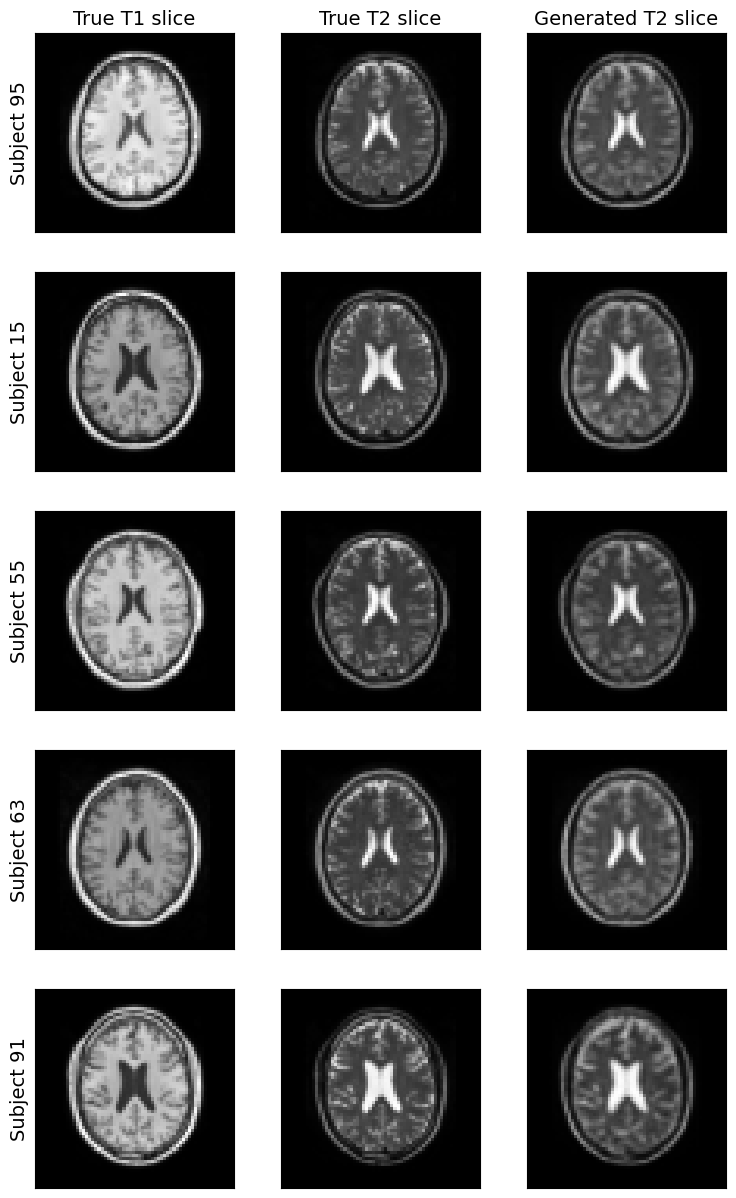

In [16]:
plot_generated_images(model_generator, dataset_val)

## Evaluating image quality

### Limitations of pixel-wise metrics such as the mean squared and absolute errors

Metrics that compare two images by averaging pixel-by-pixel comparisons, such as the mean squared error and the mean absolute error, are not necessarily the most relevant with respect to human visual perception.
*A picture is worth a thousand words*, and the image below illustrates this point:

[<img src="https://raw.githubusercontent.com/johannfaouzi/smart-data-deep-learning/main/figures/comparaison_mse_ssim.png" width="750" />](https://raw.githubusercontent.com/johannfaouzi/smart-data-deep-learning/main/figures/comparaison_mse_ssim.png)

The original image is in the top left, and the other five images are modified versions of this image characterized by (almost) the same mean squared error ($144$ with pixel values ranging from $0$ to $255$).
Yet, to human perception, some modified images are much closer to the original image than others.

### Structural Similarity Index Measure

Another possible metric for comparing two images is the **Structural Similarity Index Measure** (SSIM).
The structural similarity index measure combines three characteristics to compare two images: **luminance**, **contrast**, and **structural similarity**.

These characteristics are computed from simple metrics on the two images, such as their mean and standard deviation.
We assume that the pixel values have been normalized to the interval $[0, 1]$.
We use the following notation:
* $x$ and $y$ are two images.
* $\mu$ corresponds to the mean pixel value: $\mu_x$ for image $x$ and $\mu_y$ for image $y$.
* $\sigma$ corresponds to the standard deviation of the pixels: $\sigma_x$ for image $x$ and $\sigma_y$ for image $y$.
* $\sigma_{xy}$ corresponds to the covariance between $x$ and $y$.

**Luminance** corresponds to the mean of the pixels. To compare the luminance of two images, the following formula is used:

$$
l(x, y) = \frac{2 \mu_x \mu_y + C_1}{\mu_x^2 + \mu_y^2 + C_1}
$$

where $C_1$ is a positive constant to avoid dividing by too small a number ($C_1 = 0.01^2$ by default).
The score is indeed positive (the numerator and denominator both are), is less than or equal to 1, and equals 1 if and only if the two means are equal:

$$
(\mu_x - \mu_y)^2 \geq 0 \implies \mu_x^2 - 2 \mu_x \mu_y + \mu_y^2 \geq 0 \implies 2 \mu_x \mu_y \leq \mu_x^2 + \mu_y^2 \implies 2 \mu_x \mu_y + C_1 \leq \mu_x^2 + \mu_y^2 + C_1
$$

**Contrast**, which is a measure of pixel dispersion, corresponds to the standard deviation of the pixels. To compare the contrast of two images, the same formula as for luminance is used, replacing the means with the standard deviations:

$$
c(x, y) = \frac{2 \sigma_x \sigma_y + C_2}{\sigma_x^2 + \sigma_y^2 + C_2}
$$

where $C_2$ is a positive constant to avoid dividing by too small a number ($C_2 = 0.03^2$ by default).
The score is indeed positive (the numerator and denominator both are), is less than or equal to 1, and equals 1 if and only if the two standard deviations are equal:

$$
(\sigma_x - \sigma_y)^2 \geq 0 \implies \sigma_x^2 - 2 \sigma_x \sigma_y + \sigma_y^2 \geq 0 \implies 2 \sigma_x \sigma_y \leq \sigma_x^2 + \sigma_y^2 \implies 2 \sigma_x \sigma_y + C_2 \leq \sigma_x^2 + \sigma_y^2 + C_2
$$

**Structural similarity**, which measures the correlation between two images, corresponds to the correlation coefficient between the two images:

$$
s(x, y) = \frac{\sigma_{xy} + C_3}{\sigma_x \sigma_y + C_3}
$$

where $C_3$ is a positive constant to avoid dividing by too small a number ($C_3 = C_2 / 2$ by default).
The score lies (approximately) between $-1$ and $1$ and equals $1$ if and only if the two images are perfectly positively linearly correlated.

The **structural similarity index measure** combines these three characteristics with the following formula:

$$
\text{SSIM}(x, y) = \left[ l(x, y) \right]^\alpha \cdot \left[ c(x, y) \right]^\beta \cdot \left[ s(x, y) \right]^\gamma
$$

where the exponents $\alpha$, $\beta$, and $\gamma$ indicate the weights of the three variables in the final score.

With the default values ($\alpha = \beta = \gamma = 1$) and $C_3 = C_2 / 2$, we get the following simplified formula:

$$
\text{SSIM}(x, y) = \frac{(2 \mu_x \mu_y + C_1)(2 \sigma_{xy} + C_2)}{(\mu_x^2 + \mu_y^2 + C_1)(\sigma_x^2 + \sigma_y^2 + C_2)}
$$

Going back to the images above, we can clearly see that the modified images that seem more different from the original image to us have lower indices.

## Conditional Generative Adversarial Network (cGAN)

A generative adversarial network (GAN) is an architecture composed of two neural networks:
* The **generator** generates synthetic samples.
* The **discriminator** discriminates real samples from synthetic (generated) samples.

A conditional generative adversarial network (cGAN) is a generative adversarial network where the generator and discriminator are conditioned:
* The generator must not only generate a realistic synthetic observation, it must generate one related to the condition.
* The discriminator must not only determine whether the observation is real or synthetic, it must also determine whether the observation is related to the condition.
Indeed, the generator must not generate just any T2 image from the input T1 image (the condition).
It must generate the T2 image corresponding to the input T1 image and not to any T1 image.

Having already defined a class for the generator's architecture, all that remains is to define the discriminator.
The image below describes the architecture we will use for the discriminator:

[<img src="https://raw.githubusercontent.com/johannfaouzi/smart-data-deep-learning/main/figures/discriminator.png" width="500" />](https://raw.githubusercontent.com/johannfaouzi/smart-data-deep-learning/main/figures/discriminator.png)

### Question 5

The `Discriminator()` class defined below implements this architecture.
The architecture takes two images as input and returns a probability.
Fill in the missing code in the `__init__()` and `forward()` methods of the `Discriminator()` class using the `discriminator_block()` static method.

> **Remark**: The image is missing the flatten layer ([`torch.nn.Flatten()`](https://pytorch.org/docs/stable/generated/torch.nn.Flatten.html)) at the end of the discriminator to transform the image of size $(1, 1, 1)$, i.e., a single pixel with a single channel, into a vector of size $(1,)$, as well as the sigmoid activation function ([`torch.nn.Sigmoid()`](https://pytorch.org/docs/stable/generated/torch.nn.Sigmoid.html)) to transform the logit into a probability (these probabilities will be fed to the mean squared error loss, more details below).

> **Remark**: The class code has been made slightly more complex to make it more flexible. With this implementation, the discriminator can take as input either a single image (non-conditional discriminator) or two images (conditional discriminator) that are concatenated along the channel dimension.

In [29]:
class Discriminator(L.LightningModule):  # Always inherit from the lightning.LightningModule class
    """Class for the discriminator.

    Parameters
    ----------
    in_channels : int (default = 1)
        Number of input channels.

    condition : bool (default = True)
        Specifies whether the discriminator is conditional or not.
        If True, both images (the input and the condition) are
        concatenated along the channel dimension.
    """
    def __init__(self, in_channels=1, condition=True):
        """Constructor."""
        super().__init__()  # Always run the constructor of the parent class
        self.condition = (condition is True)

        ### BEGIN TODO ###
        model = [
            *self.discriminator_block(in_channels * (1 + self.condition), 64),
            *self.discriminator_block(64, 128),
            *self.discriminator_block(128, 256),
            *self.discriminator_block(256, 512),
            torch.nn.Conv2d(512, 1, 4, padding=0),
            torch.nn.Flatten(),
            torch.nn.Sigmoid()
        ]

        self.model = torch.nn.Sequential(*model)
        #### END TODO ####

    def forward(self, x, y):
        """Performs the forward pass.

        Parameters
        ----------
        x : Tensor, shape = (batch_size, n_channels, height, width)
            Images to classify as real or synthetic (e.g., true or generated T2-weighted images).

        y : None or Tensor, shape = (batch_size, n_channels, height, width)
            Condition (e.g., true T1-weighted images). Must be None if the discriminator is not conditional.

        Returns
        -------
        y_pred : Tensor, shape = (batch_size,)
            Probabilities that the images are real.
        """
        # If the condition y is provided, concatenate x and y along the channel dimension
        if y is not None:
            assert self.condition
            dim = 1 if x.ndim == 4 else 0
            x = torch.concat([x, y], dim=dim)
        else:
            assert not self.condition

        ### BEGIN TODO ###
        y_pred = self.model(x)
        if y_pred.ndim == 2:
            y_pred = torch.squeeze(y_pred, dim=1)
        #### END TODO ####
        return y_pred

    @staticmethod
    def discriminator_block(in_channels, out_channels):
        """Returns a convolutional block of the discriminator."""
        return [
            torch.nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=2, padding=1),
            torch.nn.LeakyReLU()
        ]

We now display a summary of our discriminator's architecture:

In [30]:
summary(Discriminator(), input_size=[(batch_size, *image_size), (batch_size, *image_size)])

Layer (type:depth-idx)                   Output Shape              Param #
Discriminator                            [32]                      --
├─Sequential: 1-1                        [32, 1]                   --
│    └─Conv2d: 2-1                       [32, 64, 32, 32]          1,216
│    └─LeakyReLU: 2-2                    [32, 64, 32, 32]          --
│    └─Conv2d: 2-3                       [32, 128, 16, 16]         73,856
│    └─LeakyReLU: 2-4                    [32, 128, 16, 16]         --
│    └─Conv2d: 2-5                       [32, 256, 8, 8]           295,168
│    └─LeakyReLU: 2-6                    [32, 256, 8, 8]           --
│    └─Conv2d: 2-7                       [32, 512, 4, 4]           1,180,160
│    └─LeakyReLU: 2-8                    [32, 512, 4, 4]           --
│    └─Conv2d: 2-9                       [32, 1, 1, 1]             8,193
│    └─Flatten: 2-10                     [32, 1]                   --
│    └─Sigmoid: 2-11                     [32, 1]               

### Question 6

Now that we have the classes for the generator and the discriminator, we can create the class implementing our conditional generative adversarial network.
The `CGAN()` class defined below implements this conditional generative adversarial network architecture.
Fill in the missing code in the `__init__()`, `discriminator_step()`, and `generator_step()` methods of the `CGAN()` class using the information provided below.

#### Architecture

We have already defined the classes for the generator and the discriminator; all that remains is to initialize these two neural networks.

#### Training

We will train the generator and the discriminator alternately, so that each pushes the other to improve:

* Regarding the **discriminator**, this is a classic binary classification problem. A batch of samples returns a batch of real T1 images and a batch of real T2 images. We use the generator to obtain the synthetic T2 images, which are detached from the computational graph with the [`torch.Tensor.detach()`](https://pytorch.org/docs/stable/generated/torch.Tensor.detach.html) method since only the parameters of the discriminator are updated in this step. We then perform the following step:
    + We feed the discriminator the real T1 images and the real T2 images, to obtain the probabilities that the real T2 images are real. We feed these probabilities into the loss function with positive labels, i.e., $1$ (since the T2 images are real here).
    + We feed the discriminator the real T1 images and the synthetic T2 images, to obtain the probabilities that the synthetic T2 images are real. We feed these probabilities into the loss function with negative labels, i.e., $0$ (since the T2 images are synthetic here). To stabilize training, **we use the mean squared error (*a.k.a. MSE loss*) instead of the binary cross-entropy loss**.

* Regarding the **generator**, the loss function has two components: one corresponding to the difference between the synthetic T2 image and the real T2 image, and one corresponding to fooling the discriminator. A batch of samples returns a batch of real T1 images and a batch of real T2 images. We use the generator to obtain the synthetic T2 images. For the first component, we use the mean absolute error (*a.k.a. L1 loss*) to measure the difference between the synthetic T2 image and the real T2 image. For the second component, this is also a binary classification problem. We feed the discriminator the real T1 images and the synthetic T2 images, to obtain the probabilities that the synthetic T2 images are real. We feed these probabilities into the loss function with positive labels, i.e., $1$ (since we want to fool the discriminator, i.e., have it classify the synthetic T2 images as real). We again use mean squared error as the loss function.

#### Evaluation

The main evaluation criterion remains the quality of the synthetic images generated by the generator.
We again use structural similarity to compare the synthetic images with the real images.

In [35]:
class CGAN(L.LightningModule):  # Always inherit from the lightning.LightningModule class
    """Class implementing our conditional generative adversarial network (cGAN).

    Parameters
    ----------
    in_channels : int (default = 1)
        Number of input channels.

    out_channels : int (default = 1)
        Number of output channels.

    lr : float (default = 1e-3)
        Learning rate.

    betas : tuple[float, float] (default = (0.9, 0.999))
        Betas hyperparameters of the Adam optimization algorithm.
    """
    def __init__(self, in_channels=1, out_channels=1, lr=1e-3, betas=(0.9, 0.999)):
        """Constructor."""
        super().__init__()  # Always run the constructor of the parent class

        self.lr = lr
        self.betas = betas

        ### BEGIN TODO ###
        # Instantiate the generator and the discriminator
        self.generator = Generator()
        self.discriminator = Discriminator()

        # Instantiate the loss functions
        self.classification_loss = torch.nn.MSELoss()
        self.reconstruction_loss = torch.nn.L1Loss()
        #### END TODO ####

        # Instantiate the metrics
        self.ssim_train = StructuralSimilarityIndexMeasure(data_range=(-1.0, 1.0))
        self.ssim_val = StructuralSimilarityIndexMeasure(data_range=(-1.0, 1.0))

        # Disable automatic optimization
        self.automatic_optimization = False

    def forward(self, x):
        """Performs the forward pass.

        Parameters
        ----------
        x : Tensor, shape = (batch_size, n_channels, height, width)
            True T1-weighted images.

        Returns
        -------
        y_pred : Tensor, shape = (batch_size, n_channels, height, width)
            Generated T2-weighted images.
        """
        return self.generator(x)

    def discriminator_step(self, x, y, dataset):
        """Performs a step for the discriminator.

        Parameters
        ----------
        x : Tensor, shape = (batch_size, n_channels, height, width)
            True T1-weighted images.

        y : Tensor, shape = (batch_size, n_channels, height, width)
            True T2-weighted images.

        dataset : {"training", "validation"}
            Step type (training or validation).

        Returns
        -------
        loss : torch.float32
            Loss function evaluated for this batch of samples.
        """
        ### BEGIN TODO ###
        # Generate the synthetic T2 images from the real T1 images
        # (detached: only the parameters of the discriminator are updated in this step)
        y_pred = self.generator(x).detach()

        # Compute the probabilities that the true (y) and synthetic (y_pred) T2 images are real
        # given the true T1 images (x)
        y_probs = self.discriminator(y, x)
        y_pred_probs = self.discriminator(y_pred, x)

        # Generate the tensors for the true (1) and synthetic (0) labels
        batch_size = x.size()[0] if x.ndim == 4 else 1
        zeros = torch.zeros(batch_size).to(self.device)
        ones = torch.ones(batch_size).to(self.device)

        # Compute the loss function
        loss = (
            self.classification_loss(y_probs, ones) + self.classification_loss(y_pred_probs, zeros)
        )

        #### END TODO ####

        name = "train" if dataset == "training" else "val"
        bar_step = dataset == "training"

        # The SSIM is only computed in the generator step
        self.log(f"loss_discriminator_{name}", loss, prog_bar=bar_step, on_step=bar_step, on_epoch=True)

        return loss

    def generator_step(self, x, y, dataset):
        """Performs a step for the generator.

        Parameters
        ----------
        x : Tensor, shape = (batch_size, n_channels, height, width)
            True T1-weighted images.

        y : Tensor, shape = (batch_size, n_channels, height, width)
            True T2-weighted images.

        dataset : {"training", "validation"}
            Step type (training or validation).

        Returns
        -------
        loss : torch.float32
            Loss function evaluated for this batch of samples.
        """
        ### BEGIN TODO ###
        # Generate the synthetic T2 images (y_pred) from the true T1 images (x)
        y_pred = self.generator(x)

        # Compute the probabilities that the synthetic T2 images (y_pred) are real
        y_pred_probs = self.discriminator(y_pred, x)

        # Generate the tensor for the true (1) labels
        batch_size = x.size()[0] if x.ndim == 4 else 1
        ones = torch.ones(batch_size).to(self.device)

        # Compute the loss function
        loss = (
            self.classification_loss(y_pred_probs, ones) + self.reconstruction_loss(y_pred, y)
        )
        #### END TODO ####

        if dataset == "training":
            metric = self.ssim_train
            name = "train"
            bar_step = True
        else:
            metric = self.ssim_val
            name = "val"
            bar_step = False

        ssim = metric(y_pred, y)
        self.log(f"loss_generator_{name}", loss, prog_bar=bar_step, on_step=bar_step, on_epoch=True)
        self.log(f"ssim_generator_{name}", ssim, prog_bar=bar_step, on_step=bar_step, on_epoch=True)

        return loss

    def training_step(self, batch):
        """Perform a training step.

        Parameters
        ----------
        batch : list[Tensor, Tensor]
            Batch of samples. The first tensor consists of the true T1-weighted images,
            while the second tensor consists of the true T2-weighted images.

        Returns
        -------
        loss : Tensor, shape = (1,)
            Loss function evaluated for this batch of samples.
        """
        x, y = batch
        optimizer_generator, optimizer_discriminator = self.optimizers()

        # Training step for the generator
        optimizer_generator.zero_grad()
        loss_generator = self.generator_step(x, y, "training")
        self.manual_backward(loss_generator)
        optimizer_generator.step()

        # Training step for the discriminator
        optimizer_discriminator.zero_grad()
        loss_discriminator = self.discriminator_step(x, y, "training")
        self.manual_backward(loss_discriminator)
        optimizer_discriminator.step()

        return loss_generator + loss_discriminator

    def validation_step(self, batch):
        """Perform a validation step.

        Parameters
        ----------
        batch : list[Tensor, Tensor]
            Batch of samples. The first tensor consists of the true T1-weighted images,
            while the second tensor consists of the true T2-weighted images.

        Returns
        -------
        loss : Tensor, shape = (1,)
            Loss function evaluated for this batch of samples.
        """
        x, y = batch

        # Disable gradient computation
        with torch.no_grad():

            # Validation step for the generator
            loss_generator = self.generator_step(x, y, "validation")

            # Validation step for the discriminator
            loss_discriminator = self.discriminator_step(x, y, "validation")

        return loss_generator + loss_discriminator

    def on_train_start(self):
        """Code to run at the beginning of training."""
        string = f"Version {self.trainer.logger.version}"
        print(f"{string}\n{'=' * len(string)}\n")

    def on_train_epoch_end(self):
        """Code to run at the end of each training epoch."""
        metrics = self.trainer.callback_metrics

        loss_gen_train = metrics['loss_generator_train'].item()
        loss_dis_train = metrics['loss_discriminator_train'].item()
        ssim_train = metrics['ssim_generator_train'].item()

        loss_gen_val = metrics['loss_generator_val'].item()
        loss_dis_val = metrics['loss_discriminator_val'].item()
        ssim_val = metrics['ssim_generator_val'].item()

        string = (f"""
            Epoch {self.trainer.current_epoch + 1} / {self.trainer.max_epochs}
            ---------------------------------------------------------------------
            |  Data set  | Generator loss | Discriminator loss | Generator SSIM |
            | ---------- | -------------- | ------------------ | -------------- |
            |  Training  |{loss_gen_train:^16.7f}|{loss_dis_train:^20.7f}|{ssim_train:^16.6f}|
            | Validation |{loss_gen_val:^16.7f}|{loss_dis_val:^20.7f}|{ssim_val:^16.6f}|
            ---------------------------------------------------------------------
        """)
        string = "\n".join([line.strip() for line in string.strip().split("\n")])
        print(string, "\n")

    def configure_optimizers(self):
        """Configure the optimization algorithms."""
        optimizer_generator = torch.optim.Adam(
            self.generator.parameters(), lr=self.lr, betas=self.betas
        )

        optimizer_discriminator = torch.optim.Adam(
            self.discriminator.parameters(), lr=self.lr, betas=self.betas
        )
        return [optimizer_generator, optimizer_discriminator]

We now train our cGAN for $20$ epochs.
Note that, compared to the generator alone, **we use a lower learning rate**.
This is necessary so that the discriminator does not become much better than the generator, which would prevent the generator from improving (this is our main goal, the discriminator is only a tool to help the generator).

In [ ]:
from lightning.pytorch.callbacks import TQDMProgressBar
from lightning.pytorch.loggers import CSVLogger


model_cgan = CGAN(lr=1e-4)

trainer_cgan = L.Trainer(
    max_epochs=20,
    enable_model_summary=False,
    logger=CSVLogger('.'),
    num_sanity_val_steps=0,
    log_every_n_steps=10,
    callbacks=[TQDMProgressBar(refresh_rate=5)]
)

trainer_cgan.fit(
    model=model_cgan,
    train_dataloaders=dataloader_train,
    val_dataloaders=dataloader_val
)

Training: |          | 0/? [00:00<?, ?it/s]

Version 3



Validation: |          | 0/? [00:00<?, ?it/s]

Epoch 1 / 20
---------------------------------------------------------------------
|  Data set  | Generator loss | Discriminator loss | Generator SSIM |
| ---------- | -------------- | ------------------ | -------------- |
|  Training  |   0.6712866    |     0.4741809      |    0.251955    |
| Validation |   0.4659888    |     0.4697292      |    0.458420    |
--------------------------------------------------------------------- 



Validation: |          | 0/? [00:00<?, ?it/s]

Epoch 2 / 20
---------------------------------------------------------------------
|  Data set  | Generator loss | Discriminator loss | Generator SSIM |
| ---------- | -------------- | ------------------ | -------------- |
|  Training  |   0.4114256    |     0.4880572      |    0.530904    |
| Validation |   0.3828736    |     0.4844173      |    0.609183    |
--------------------------------------------------------------------- 



... (6 outputs left out)

Validation: |          | 0/? [00:00<?, ?it/s]

Epoch 6 / 20
---------------------------------------------------------------------
|  Data set  | Generator loss | Discriminator loss | Generator SSIM |
| ---------- | -------------- | ------------------ | -------------- |
|  Training  |   0.3408464    |     0.5063155      |    0.758661    |
| Validation |   0.3271296    |     0.4966765      |    0.761002    |
--------------------------------------------------------------------- 



Validation: |          | 0/? [00:00<?, ?it/s]

Epoch 7 / 20
---------------------------------------------------------------------
|  Data set  | Generator loss | Discriminator loss | Generator SSIM |
| ---------- | -------------- | ------------------ | -------------- |
|  Training  |   0.3345087    |     0.4980223      |    0.769982    |
| Validation |   0.3310201    |     0.4991004      |    0.762454    |
--------------------------------------------------------------------- 



### Question 7

Visualize a few images generated by the cGAN's generator using the `plot_generated_images()` function defined above.
Compare the performance of the cGAN's generator with the generator and explain the difference.
Suggest ways to improve it.

In [ ]:
# TODO

**Answer**: TODO

## CycleGAN

A cyclic generative adversarial network (CycleGAN) is an **unsupervised** image translation model.
This approach is based on two generative adversarial networks and is trained on **unpaired data**.
We will therefore no longer use this property of our dataset and will act as if the data were unpaired.

Image translation is a **conditional** generative method.
We do not want to obtain just any output image, but an image related to the input image.
When we have access to paired data, i.e., the original image and its translation, we can train a conditional generative model as we did in the first part of this notebook.
However, this approach is impossible if we do not have access to paired data, which is often the case.

To address this problem, the main innovation of *CycleGANs* is to use **two generative adversarial networks** (GANs) and introduce the concept of **cycle consistency**: if we generate a synthetic image in domain *Y* from an original image in domain *X*, and then generate a synthetic image in domain *X* from the synthetic image in domain *Y*, then the two images in domain *X* (the original image and the generated image) must be very close.
Indeed, if the image generated in domain *Y* does not contain the characteristics of the original image, then it will be impossible to have an image generated in domain *X*, generated from the image generated in domain *Y*, close to the original image.

The image below summarizes the main concepts of a CycleGAN:

[<img src="https://raw.githubusercontent.com/johannfaouzi/smart-data-deep-learning/main/figures/cycle_consistency.png" width="750" />](https://raw.githubusercontent.com/johannfaouzi/smart-data-deep-learning/main/figures/cycle_consistency.png)

### Question 8

The `CycleGAN()` class defined below implements this cyclic generative adversarial network architecture.
Fill in the missing code in the `__init__()`, `discriminators_step()`, and `generators_step()` methods of the `CycleGAN()` class using the information provided below.

#### Architecture

Both networks have the same architecture, namely:

* For the generators, we use the architecture already defined in the `Generator()` class.

* For the discriminators, we use the architecture defined in the `Discriminator()` class.

#### Training

We will train the generators and the discriminators alternately, so that each pushes the others to improve:

* Regarding the **discriminators**, these are two classic binary classification problems. A batch of samples returns a batch of real T1 images and a batch of real T2 images. We will also use the two generators to obtain a batch of synthetic T1 images and a batch of synthetic T2 images (detached from the computational graph with the `detach()` method since only the parameters of the discriminators are updated in this step). We feed the real and synthetic T1 images into the T1 discriminator to obtain its predictions (forward pass), evaluate the loss function to compute the gradients (backward pass), and update the trainable parameter values of the T1 discriminator. We do the same for the T2 discriminator. However, we will use a different loss function than cross-entropy. Indeed, a technique to stabilize training and generate better images is to **replace cross-entropy with mean squared error** (*a.k.a. MSE loss*).

* Regarding the **generators**, training is a bit more complex. First, there is the part that consists of fooling the discriminators, i.e., the same binary classification problem as for the discriminators but with reversed labels: the labels must be *real* for the generated images and *generated* for the real images. Finally, we need to add the terms for cycle consistency: we will use the mean absolute error (*a.k.a. L1 loss*) between the real image and the synthetic image (in the same domain).

#### Evaluation

The main evaluation criterion remains the quality of the synthetic images generated by the generator from domain $T1$ to domain $T2$.
We again use structural similarity to compare the synthetic images with the real images.

In [ ]:
import itertools


class CycleGAN(L.LightningModule):  # Always inherit from the lightning.LightningModule class
    """Class implementing our cycle generative adversarial network (CycleGAN).

    Parameters
    ----------
    in_channels : int (default = 1)
        Number of input channels.

    out_channels : int (default = 1)
        Number of output channels.

    lr : float (default = 1e-3)
        Learning rate.

    betas : tuple[float, float] (default = (0.9, 0.999))
        Betas hyperparameters of the Adam optimization algorithms.
    """
    def __init__(self, in_channels=1, out_channels=1, lr=1e-3, betas=(0.9, 0.999)):
        """Constructor."""
        super().__init__()  # Always run the constructor of the parent class

        self.lr = lr
        self.betas = betas

        ### BEGIN TODO ###
        # Instantiate the generators and the discriminators
        # self.generator_from_t1_to_t2 =
        # self.generator_from_t2_to_t1 =
        # self.discriminator_t1 =
        # self.discriminator_t2 =

        # Instantiate the loss functions
        #### END TODO ####

        # Instantiate the metrics
        self.ssim_train = StructuralSimilarityIndexMeasure(data_range=(-1.0, 1.0))
        self.ssim_val = StructuralSimilarityIndexMeasure(data_range=(-1.0, 1.0))

        # Disable automatic optimization
        self.automatic_optimization = False

    def forward(self, x):
        """Performs the forward pass.

        Parameters
        ----------
        x : Tensor, shape = (batch_size, n_channels, height, width)
            True T1-weighted images.

        Returns
        -------
        y_pred : Tensor, shape = (batch_size, n_channels, height, width)
            Generated T2-weighted images.
        """
        return self.generator_from_t1_to_t2(x)

    def discriminators_step(self, x, y, dataset):
        """Performs a step for the discriminators.

        Parameters
        ----------
        x : Tensor, shape = (batch_size, n_channels, height, width)
            True T1-weighted images.

        y : Tensor, shape = (batch_size, n_channels, height, width)
            True T2-weighted images.

        dataset : {"training", "validation"}
            Step type (training or validation).

        Returns
        -------
        loss : torch.float32
            Loss function evaluated for this batch of samples.
        """
        ### BEGIN TODO ###
        # Generate the synthetic T1 (x_pred) and T2 (y_pred) images from the true T2 (y) and T1 (x) images
        # (detached: only the parameters of the discriminators are updated in this step)
        # x_pred =
        # y_pred =

        # Compute the probabilities for the true and synthetic T1 and T2 images of being real

        # Generate the tensors for the true (1) and synthetic (0) labels

        # Compute the loss function
        # loss =
        #### END TODO ####

        name = "train" if dataset == "training" else "val"
        bar_step = dataset == "training"

        # The SSIM is only computed in the generator step
        self.log(f"loss_discriminators_{name}", loss, prog_bar=bar_step, on_step=bar_step, on_epoch=True)

        return loss

    def generators_step(self, x, y, dataset):
        """Performs a step for the generators.

        Parameters
        ----------
        x : Tensor, shape = (batch_size, n_channels, height, width)
            True T1-weighted images.

        y : Tensor, shape = (batch_size, n_channels, height, width)
            True T2-weighted images.

        dataset : {"training", "validation"}
            Step type (training or validation).

        Returns
        -------
        loss : torch.float32
            Loss function evaluated for this batch of samples.
        """
        ### BEGIN TODO ###
        # Generate the synthetic T1 and T2 images from the real T2 and T1 images
        # x_pred =
        # y_pred =

        # Generate the synthetic T1 and T2 images from the synthetic T2 and T1 images
        # x_pred_pred =
        # y_pred_pred =

        # Compute the probabilities for the synthetic T1 (x_pred) and T2 (y_pred) images of being real

        # Generate the tensors for the true (1) labels

        # Compute the loss function
        # loss =
        #### END TODO ####

        if dataset == "training":
            metric = self.ssim_train
            name = "train"
            bar_step = True
        else:
            metric = self.ssim_val
            name = "val"
            bar_step = False

        ssim = metric(y_pred, y)
        self.log(f"loss_generators_{name}", loss, prog_bar=bar_step, on_step=bar_step, on_epoch=True)
        self.log(f"ssim_generators_{name}", ssim, prog_bar=bar_step, on_step=bar_step, on_epoch=True)

        return loss

    def training_step(self, batch):
        """Perform a training step.

        Parameters
        ----------
        batch : list[Tensor, Tensor]
            Batch of samples. The first tensor consists of the true T1-weighted images,
            while the second tensor consists of the true T2-weighted images.

        Returns
        -------
        loss : Tensor, shape = (1,)
            Loss function evaluated for this batch of samples.
        """
        x, y = batch
        optimizer_generators, optimizer_discriminators = self.optimizers()

        # Training step for the generators
        optimizer_generators.zero_grad()
        loss_generators = self.generators_step(x, y, "training")
        self.manual_backward(loss_generators)
        optimizer_generators.step()

        # Training step for the discriminators
        optimizer_discriminators.zero_grad()
        loss_discriminators = self.discriminators_step(x, y, "training")
        self.manual_backward(loss_discriminators)
        optimizer_discriminators.step()

        return loss_generators + loss_discriminators

    def validation_step(self, batch):
        """Perform a validation step.

        Parameters
        ----------
        batch : list[Tensor, Tensor]
            Batch of samples. The first tensor consists of the true T1-weighted images,
            while the second tensor consists of the true T2-weighted images.

        Returns
        -------
        loss : Tensor, shape = (1,)
            Loss function evaluated for this batch of samples.
        """
        x, y = batch

        # Disable gradient computation
        with torch.no_grad():

            # Validation step for the generators
            loss_generators = self.generators_step(x, y, "validation")

            # Validation step for the discriminators
            loss_discriminators = self.discriminators_step(x, y, "validation")

        return loss_generators + loss_discriminators

    def on_train_start(self):
        """Code to run at the beginning of training."""
        string = f"Version {self.trainer.logger.version}"
        print(f"{string}\n{'=' * len(string)}\n")

    def on_train_epoch_end(self):
        """Code to run at the end of each training epoch."""
        metrics = self.trainer.callback_metrics

        loss_gen_train = metrics['loss_generators_train'].item()
        loss_dis_train = metrics['loss_discriminators_train'].item()
        ssim_train = metrics['ssim_generators_train'].item()

        loss_gen_val = metrics['loss_generators_val'].item()
        loss_dis_val = metrics['loss_discriminators_val'].item()
        ssim_val = metrics['ssim_generators_val'].item()

        string = (f"""
            Epoch {self.trainer.current_epoch + 1} / {self.trainer.max_epochs}
            -----------------------------------------------------------------------
            |  Data set  | Generators loss | Discriminators loss | Generator SSIM |
            | ---------- | --------------- | ------------------- | -------------- |
            |  Training  |{loss_gen_train:^17.5f}|{loss_dis_train:^21.5f}|{ssim_train:^16.6f}|
            | Validation |{loss_gen_val:^17.5f}|{loss_dis_val:^21.5f}|{ssim_val:^16.6f}|
            -----------------------------------------------------------------------
        """)
        string = "\n".join([line.strip() for line in string.strip().split("\n")])
        print(string, "\n")

    def configure_optimizers(self):
        """Configure the optimization algorithms."""
        optimizer_generators = torch.optim.Adam(itertools.chain(
            self.generator_from_t1_to_t2.parameters(), self.generator_from_t2_to_t1.parameters()
        ), lr=self.lr, betas=self.betas)

        optimizer_discriminators = torch.optim.Adam(itertools.chain(
            self.discriminator_t1.parameters(), self.discriminator_t2.parameters()
        ), lr=self.lr, betas=self.betas)

        return [optimizer_generators, optimizer_discriminators]

We will now train our model for $20$ epochs.
For the same reasons as for the cGAN, **we use a lower learning rate**.

In [ ]:
from lightning.pytorch.callbacks import TQDMProgressBar
from lightning.pytorch.loggers import CSVLogger


model_cyclegan = CycleGAN(lr=1e-4)

trainer_cyclegan = L.Trainer(
    max_epochs=20,
    enable_model_summary=False,
    logger=CSVLogger('.'),
    num_sanity_val_steps=0,
    log_every_n_steps=10,
    callbacks=[TQDMProgressBar(refresh_rate=5)]
)

trainer_cyclegan.fit(
    model=model_cyclegan,
    train_dataloaders=dataloader_train,
    val_dataloaders=dataloader_val
)

### Question 9

Visualize a few images generated by the CycleGAN's generator using the `plot_generated_images()` function defined above.
Compare the performance of the CycleGAN's generator to the other generators and explain the difference.
Suggest ways to improve it.

In [ ]:
# TODO

**Answer**: TODO